In [1]:
pip install lightgbm optuna joblib pandas numpy scikit-learn matplotlib seaborn kagglehub

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
# %% [markdown]
# # Optimised Crop Yield Prediction Model
# Steps: feature engineering -> LightGBM (default) -> Optuna tuning -> final model
# Compares against the basic models and saves the model for the SHAP step.
#
# Install once:  pip install lightgbm optuna joblib pandas numpy scikit-learn matplotlib seaborn kagglehub

# %% 1. Imports
import glob
import os
import warnings

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
N_TRIALS = 30          # increase to 50-100 for a better search (takes longer)
TARGET = "crop_yield_tons"


In [3]:
# %% 2. Load data (same steps as the basic model so the split is identical)
try:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download(
        "hvanman2code/agricultural-yield-prediction-dataset-247k-rows"
    )
except Exception as e:
    print("kagglehub download failed:", e)
    DATA_DIR = "data"

csv_files = glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
assert csv_files, "No CSV found. Set DATA_DIR to the folder containing the CSV."
df = pd.read_csv(max(csv_files, key=os.path.getsize))
df = df.drop_duplicates().reset_index(drop=True)
df = df.dropna(subset=[TARGET])
print("Shape:", df.shape)

Shape: (247319, 18)


In [4]:
# %% 3. Feature engineering
CAT_COLS = ["weather_zone", "irrigation_method", "seed_quality",
            "soil_type", "fertilized", "season", "crop_type"]
RAW_NUM = ["soil_ph", "irrigation_mm", "days_from_last_harvest", "nitrogen_kg_ha",
           "rainfall_mm", "avg_temp_c", "phosphorus_kg_ha", "humidity_pct",
           "pest_index", "potassium_kg_ha"]


def add_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    eps = 1e-6

    # 1) Missing-value flags (missingness itself may carry information)
    for c in ["soil_ph", "phosphorus_kg_ha", "potassium_kg_ha"]:
        d[f"{c}_missing"] = d[c].isna().astype(int)

    # 2) Soil nutrient features
    d["npk_total"] = d[["nitrogen_kg_ha", "phosphorus_kg_ha",
                        "potassium_kg_ha"]].sum(axis=1, min_count=1)
    d["n_to_p"] = d["nitrogen_kg_ha"] / (d["phosphorus_kg_ha"] + eps)
    d["n_to_k"] = d["nitrogen_kg_ha"] / (d["potassium_kg_ha"] + eps)
    d["p_to_k"] = d["phosphorus_kg_ha"] / (d["potassium_kg_ha"] + eps)
    d["ph_deviation"] = (d["soil_ph"] - 6.5).abs()       # distance from near-neutral pH

    # 3) Climate / water features
    d["total_water_mm"] = d["rainfall_mm"] + d["irrigation_mm"]
    d["rain_x_temp"] = d["rainfall_mm"] * d["avg_temp_c"]
    d["temp_sq"] = d["avg_temp_c"] ** 2                   # captures optimum temperature
    d["rain_per_humidity"] = d["rainfall_mm"] / (d["humidity_pct"] + eps)
    d["water_stress"] = d["avg_temp_c"] / (d["total_water_mm"] + eps)

    # 4) Categorical -> pandas 'category' (LightGBM handles these natively)
    for c in CAT_COLS:
        d[c] = d[c].astype("category")
    return d


X_raw = df.drop(columns=[TARGET]).copy()
for c in CAT_COLS:
    X_raw[c] = X_raw[c].astype("category")
X_fe = add_features(df.drop(columns=[TARGET]))
y = df[TARGET]
print("Features: raw =", X_raw.shape[1], "| engineered =", X_fe.shape[1])

Features: raw = 17 | engineered = 30


In [5]:
# %% 4. Splits: train / validation (for tuning) / test (untouched until the end)
# Same test split as the basic model (test_size=0.2, random_state=42)
idx_train, idx_test = train_test_split(
    df.index, test_size=0.2, random_state=RANDOM_STATE
)
idx_tr, idx_val = train_test_split(
    idx_train, test_size=0.15, random_state=RANDOM_STATE
)
print(f"Train: {len(idx_tr)} | Validation: {len(idx_val)} | Test: {len(idx_test)}")


def split(X):
    return (X.loc[idx_tr], X.loc[idx_val], X.loc[idx_test])


Xr_tr, Xr_val, Xr_te = split(X_raw)
Xf_tr, Xf_val, Xf_te = split(X_fe)
y_tr, y_val, y_te = y.loc[idx_tr], y.loc[idx_val], y.loc[idx_test]


def evaluate(model, X_a, y_a, X_b, y_b, name):
    return {
        "Model": name,
        "Train R2": r2_score(y_a, model.predict(X_a)),
        "Test R2": r2_score(y_b, model.predict(X_b)),
        "RMSE": np.sqrt(mean_squared_error(y_b, model.predict(X_b))),
        "MAE": mean_absolute_error(y_b, model.predict(X_b)),
    }


def fit_lgb(params, X_t, y_t, X_v, y_v):
    m = lgb.LGBMRegressor(
        n_estimators=5000, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1, **params
    )
    m.fit(X_t, y_t, eval_set=[(X_v, y_v)], eval_metric="rmse",
          callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)])
    return m


Train: 168176 | Validation: 29679 | Test: 49464


In [6]:
# %% 5. LightGBM with default parameters: raw features vs engineered features
# This shows how much gain comes from feature engineering alone.
lgb_raw = fit_lgb({}, Xr_tr, y_tr, Xr_val, y_val)
lgb_fe = fit_lgb({}, Xf_tr, y_tr, Xf_val, y_val)

results = [
    evaluate(lgb_raw, Xr_tr, y_tr, Xr_te, y_te, "LightGBM default (raw features)"),
    evaluate(lgb_fe, Xf_tr, y_tr, Xf_te, y_te, "LightGBM default (+ engineered features)"),
]
print(pd.DataFrame(results).set_index("Model").round(4))

                                          Train R2  Test R2    RMSE     MAE
Model                                                                      
LightGBM default (raw features)             0.8636   0.8401  1.7656  1.3917
LightGBM default (+ engineered features)    0.8606   0.8396  1.7688  1.3939


In [7]:
# %% 6-7. Final tuned model (best parameters from earlier Optuna search, 30 trials)
import time

best_params = {
    'learning_rate': 0.02381192195013875,
    'num_leaves': 250,
    'max_depth': 4,
    'min_child_samples': 125,
    'subsample': 0.648571161611966,
    'colsample_bytree': 0.9092699553859992,
    'reg_alpha': 0.8469832240686257,
    'reg_lambda': 0.0018588562541551896,
    'subsample_freq': 1,
}

t0 = time.time()
final_model = fit_lgb(best_params, Xf_tr, y_tr, Xf_val, y_val)
final_fit_time = time.time() - t0
print("Best iteration:", final_model.best_iteration_,
      "| fit time:", round(final_fit_time, 1), "s")

results.append(evaluate(final_model, Xf_tr, y_tr, Xf_te, y_te,
                        "LightGBM tuned (Optuna) + engineered features"))

Best iteration: 3195 | fit time: 57.6 s



=== Basic vs Optimised ===
                            Train R2  Test R2    RMSE     MAE  Fit time (s)  \
Model                                                                         
Linear Regression (basic)     0.4401   0.4378  3.3111  2.6598        5.8069   
Random Forest (basic)         0.9718   0.7994  1.9779  1.5671     3001.2968   
LightGBM tuned (optimised)    0.8549   0.8446  1.7406  1.3702       57.5960   

                            Overfit gap  RMSE reduction vs this model (%)  
Model                                                                      
Linear Regression (basic)        0.0023                           47.4303  
Random Forest (basic)            0.1724                           11.9978  
LightGBM tuned (optimised)       0.0103                            0.0000  


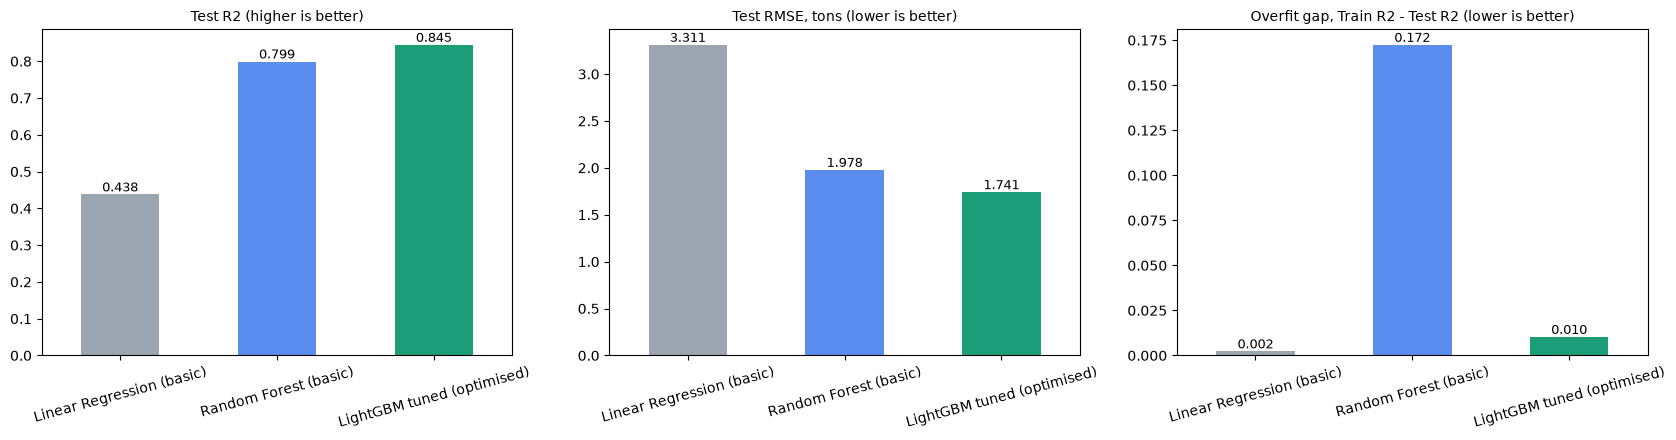

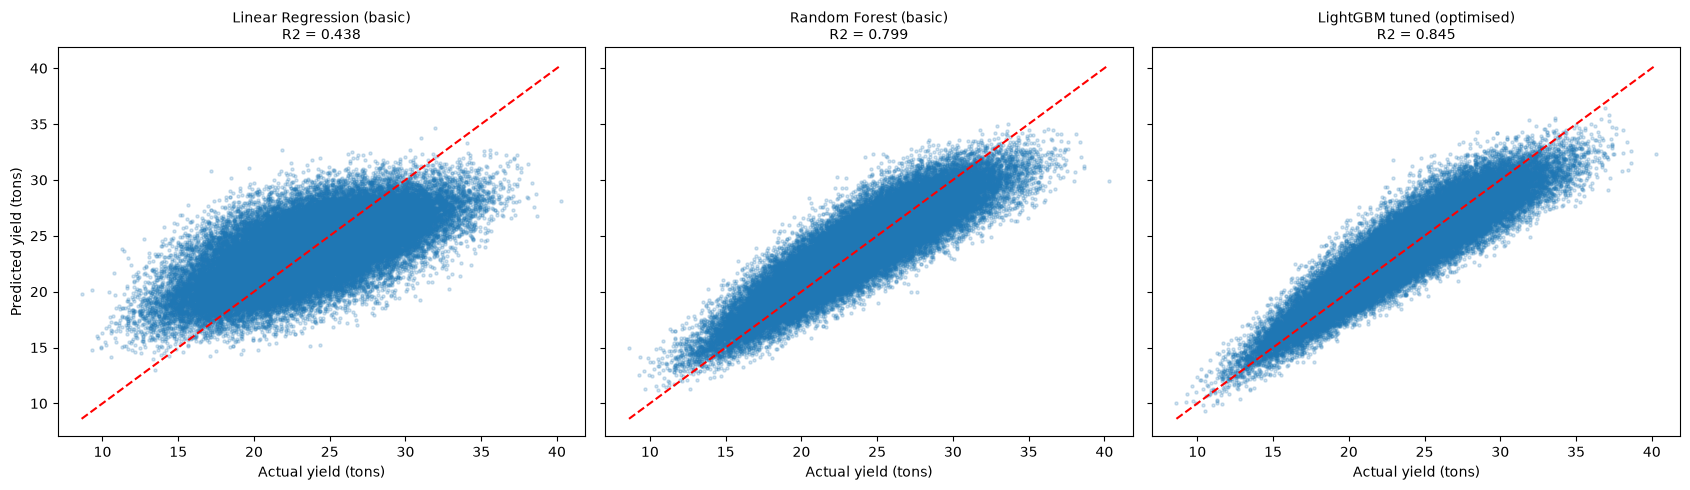


RMSE by crop type:
          Linear Regression (basic)  Random Forest (basic)  \
crop                                                        
corn                         3.313                  2.090   
cotton                       3.236                  1.821   
rice                         3.039                  1.731   
soybean                      3.220                  2.111   
wheat                        3.623                  2.055   

         LightGBM tuned (optimised)  
crop                                 
corn                          1.899  
cotton                        1.563  
rice                          1.514  
soybean                       1.797  
wheat                         1.817  


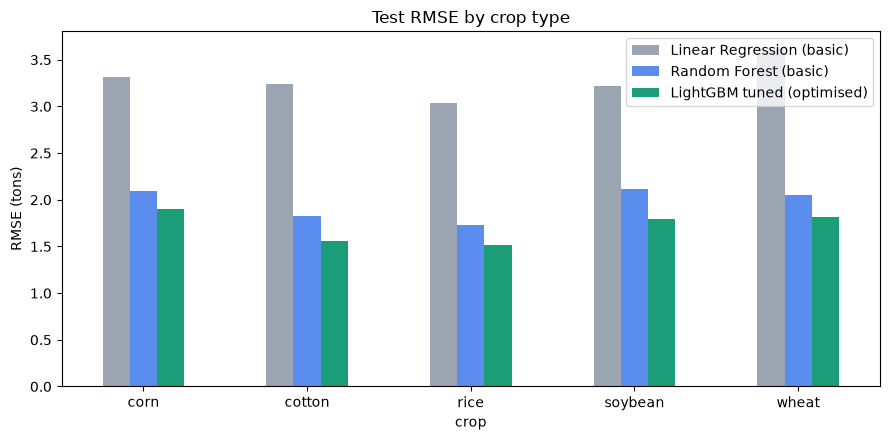

In [8]:
# %% 8. Basic vs optimised comparison (replaces the old section 8)
# Paste this cell AFTER section 7 of optimised_crop_yield_model.py.
# It retrains the basic models on the SAME split, so nothing is typed in by hand.
import time

import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --- 8a. Basic models on the same train/test rows -------------------------------
X_basic = df.drop(columns=[TARGET]).copy()
for c in CAT_COLS:
    X_basic[c] = X_basic[c].astype(object)          # plain strings for OneHotEncoder
Xb_train, Xb_test = X_basic.loc[idx_train], X_basic.loc[idx_test]
yb_train = y.loc[idx_train]

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), RAW_NUM),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), CAT_COLS),
])

basic_models = {
    "Linear Regression (basic)": LinearRegression(),
    "Random Forest (basic)": RandomForestRegressor(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
}

rows, test_preds = [], {}
for name, est in basic_models.items():
    pipe = Pipeline([("prep", preprocess), ("model", est)])
    t0 = time.time()
    pipe.fit(Xb_train, yb_train)
    fit_time = time.time() - t0
    p_te = pipe.predict(Xb_test)
    test_preds[name] = p_te
    rows.append({
        "Model": name,
        "Train R2": r2_score(yb_train, pipe.predict(Xb_train)),
        "Test R2": r2_score(y_te, p_te),
        "RMSE": np.sqrt(mean_squared_error(y_te, p_te)),
        "MAE": mean_absolute_error(y_te, p_te),
        "Fit time (s)": fit_time,
    })

# --- 8b. Optimised model (already trained above) --------------------------------
p_opt = final_model.predict(Xf_te)
test_preds["LightGBM tuned (optimised)"] = p_opt
rows.append({
    "Model": "LightGBM tuned (optimised)",
    "Train R2": r2_score(y_tr, final_model.predict(Xf_tr)),
    "Test R2": r2_score(y_te, p_opt),
    "RMSE": np.sqrt(mean_squared_error(y_te, p_opt)),
    "MAE": mean_absolute_error(y_te, p_opt),
    "Fit time (s)": final_fit_time,
})

comparison = pd.DataFrame(rows).set_index("Model")
comparison["Overfit gap"] = comparison["Train R2"] - comparison["Test R2"]

# Improvement of the optimised model over each basic model
opt = comparison.loc["LightGBM tuned (optimised)"]
comparison["RMSE reduction vs this model (%)"] = (
    (comparison["RMSE"] - opt["RMSE"]) / comparison["RMSE"] * 100
)
print("\n=== Basic vs Optimised ===")
print(comparison.round(4))
comparison.to_csv("basic_vs_optimised_comparison.csv")

# --- 8c. Charts -----------------------------------------------------------------
colors = ["#9aa5b1", "#5b8def", "#1b9e77"]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, metric, title in zip(ax, ["Test R2", "RMSE", "Overfit gap"],
                            ["Test R2 (higher is better)",
                             "Test RMSE, tons (lower is better)",
                             "Overfit gap, Train R2 - Test R2 (lower is better)"]):
    comparison[metric].plot(kind="bar", ax=a, color=colors, rot=15)
    a.set_title(title, fontsize=10)
    a.set_xlabel("")
    for p in a.patches:
        a.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
lims = [y_te.min(), y_te.max()]
for a, (name, p) in zip(ax, test_preds.items()):
    a.scatter(y_te, p, alpha=0.2, s=5)
    a.plot(lims, lims, "r--")
    a.set_title(f"{name}\nR2 = {r2_score(y_te, p):.3f}", fontsize=10)
    a.set_xlabel("Actual yield (tons)")
ax[0].set_ylabel("Predicted yield (tons)")
plt.tight_layout()
plt.show()

# --- 8d. Where does the optimised model help most? RMSE by crop type -----------
crop_te = df.loc[idx_test, "crop_type"].astype(str)
per_crop = {}
for name, p in test_preds.items():
    err = pd.DataFrame({"crop": crop_te.values, "se": (y_te.values - p) ** 2})
    per_crop[name] = np.sqrt(err.groupby("crop")["se"].mean())
per_crop = pd.DataFrame(per_crop)
print("\nRMSE by crop type:\n", per_crop.round(3))

per_crop.plot(kind="bar", figsize=(9, 4.5), color=colors, rot=0)
plt.title("Test RMSE by crop type")
plt.ylabel("RMSE (tons)")
plt.tight_layout()
plt.show()

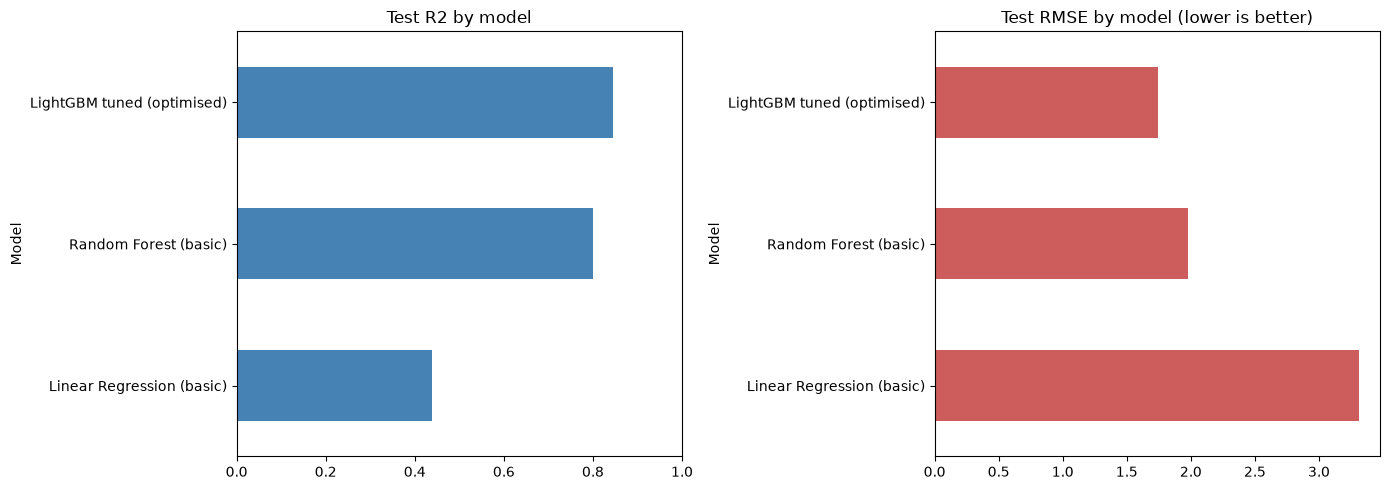

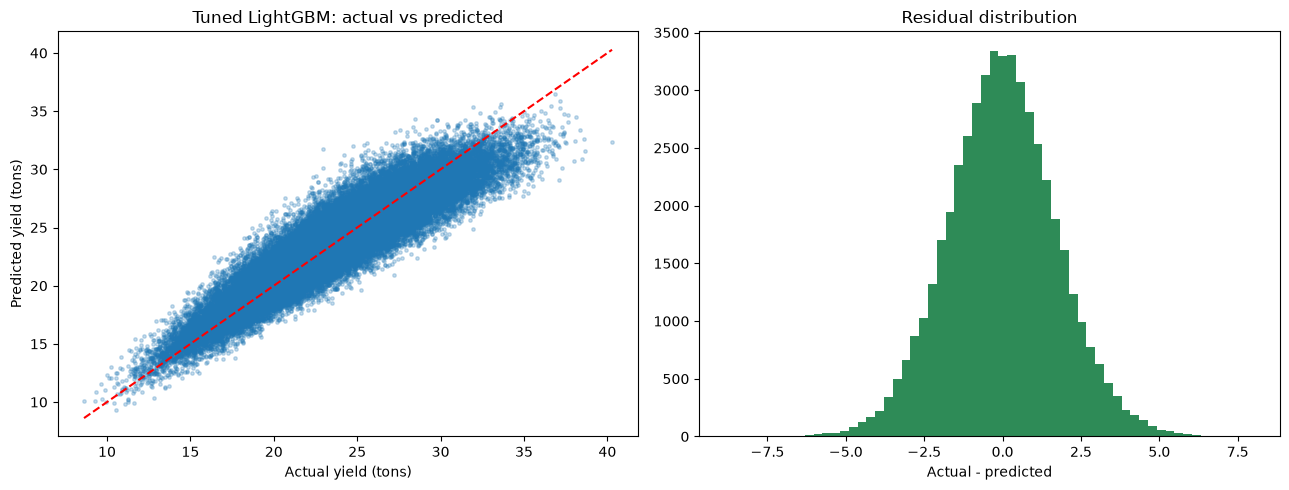

In [9]:
# %% 9. Plots: comparison, actual vs predicted, residuals
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
comparison["Test R2"].plot(kind="barh", ax=ax[0], color="steelblue")
ax[0].set_title("Test R2 by model")
ax[0].set_xlim(0, 1)
comparison["RMSE"].plot(kind="barh", ax=ax[1], color="indianred")
ax[1].set_title("Test RMSE by model (lower is better)")
plt.tight_layout()
plt.show()

pred = final_model.predict(Xf_te)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_te, pred, alpha=0.25, s=6)
lims = [min(y_te.min(), pred.min()), max(y_te.max(), pred.max())]
ax[0].plot(lims, lims, "r--")
ax[0].set_xlabel("Actual yield (tons)")
ax[0].set_ylabel("Predicted yield (tons)")
ax[0].set_title("Tuned LightGBM: actual vs predicted")
ax[1].hist(y_te - pred, bins=60, color="seagreen")
ax[1].set_title("Residual distribution")
ax[1].set_xlabel("Actual - predicted")
plt.tight_layout()
plt.show()




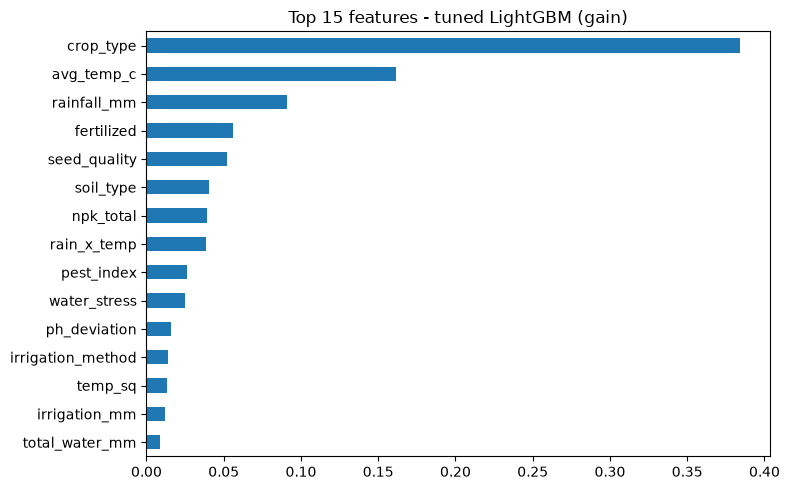

crop_type            0.3845
avg_temp_c           0.1616
rainfall_mm          0.0906
fertilized           0.0562
seed_quality         0.0521
soil_type            0.0408
npk_total            0.0391
rain_x_temp          0.0385
pest_index           0.0264
water_stress         0.0252
ph_deviation         0.0157
irrigation_method    0.0137
temp_sq              0.0133
irrigation_mm        0.0122
total_water_mm       0.0090
dtype: float64


In [10]:
# %% 10. Built-in feature importance (gain) of the tuned model
imp = pd.Series(final_model.booster_.feature_importance(importance_type="gain"),
                index=Xf_tr.columns)
imp = (imp / imp.sum()).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5))
imp[::-1].plot(kind="barh")
plt.title("Top 15 features - tuned LightGBM (gain)")
plt.tight_layout()
plt.show()
print(imp.round(4))

In [11]:
# %% 11. Save everything needed for the SHAP / explainability step
joblib.dump(
    {"model": final_model, "X_train": Xf_tr, "X_test": Xf_te, "y_test": y_te,
     "feature_names": list(Xf_tr.columns), "best_params": best_params},
    "optimised_model_bundle.joblib",
)
print("Saved: optimised_model_bundle.joblib, basic_vs_optimised_comparison.csv")

Saved: optimised_model_bundle.joblib, basic_vs_optimised_comparison.csv


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Xs = Xf_te.sample(10000, random_state=42)          # 10,000 test rows is enough

contrib = final_model.predict(Xs, pred_contrib=True)   # LightGBM computes SHAP for us
shap_vals = pd.DataFrame(contrib[:, :-1], columns=Xs.columns, index=Xs.index)
base_value = contrib[0, -1]

print("Average predicted yield (starting point):", round(base_value, 2), "tons")
shap_vals.head()

Average predicted yield (starting point): 23.72 tons


,weather_zone,irrigation_method,soil_ph,irrigation_mm,days_from_last_harvest,seed_quality,soil_type,fertilized,nitrogen_kg_ha,season,...,npk_total,n_to_p,n_to_k,p_to_k,ph_deviation,total_water_mm,rain_x_temp,temp_sq,rain_per_humidity,water_stress
243380,-0.002466,-0.591042,0.018951,0.076285,-0.008795,-0.375467,-1.330640,0.567000,-0.025575,0.004997,...,0.064348,-0.041497,-0.023241,-0.039075,0.440623,0.073470,-0.055548,0.083599,-0.000007,0.177412
216101,-0.022011,-0.620759,0.011074,0.272272,-0.001201,-1.394902,0.965854,0.567081,-0.056741,-0.006809,...,0.018481,0.029170,0.011994,-0.026007,0.431071,0.080035,-0.408018,-0.017609,-0.019573,0.141929
55821,0.010967,0.116104,0.011387,0.037190,-0.008466,-0.399632,-1.270873,0.572908,-0.066329,-0.005439,...,-0.429030,0.002036,0.010431,-0.077873,0.523806,0.004192,-0.159269,-0.152413,0.007527,0.079926
115802,0.000941,0.131807,-0.012613,0.339936,0.005883,-1.222593,-1.226933,-1.566426,0.078224,0.001341,...,0.689284,-0.038884,-0.022810,-0.083374,0.460117,0.078302,0.119922,-0.090138,-0.011057,-0.102262
97123,0.010567,0.127133,0.009488,0.436748,-0.009005,-0.401707,-1.344109,0.561446,-0.064746,-0.005313,...,-0.446959,-0.003361,0.025799,-0.072602,0.519785,0.106868,0.230262,0.067681,0.028915,0.201551


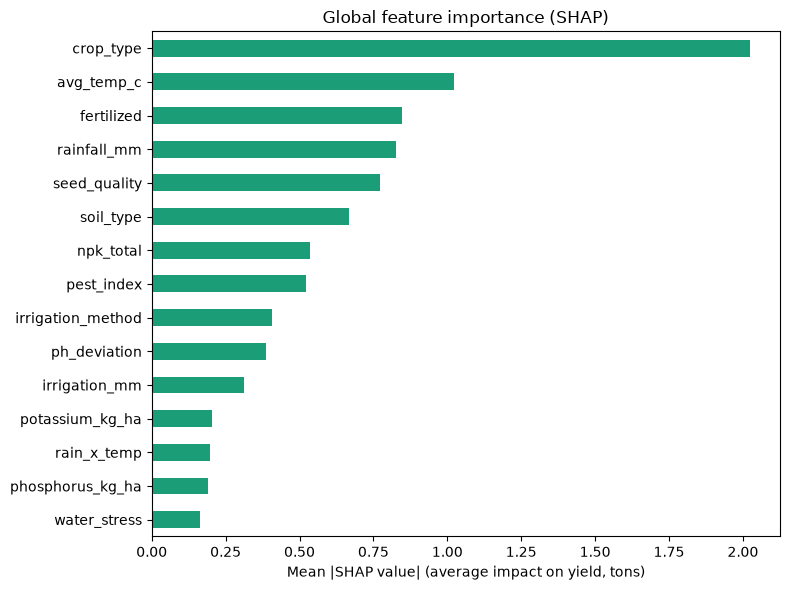

In [13]:
mean_abs = shap_vals.abs().mean().sort_values(ascending=False)

plt.figure(figsize=(8, 6))
mean_abs.head(15)[::-1].plot(kind="barh", color="#1b9e77")
plt.xlabel("Mean |SHAP value| (average impact on yield, tons)")
plt.title("Global feature importance (SHAP)")
plt.tight_layout()
plt.show()

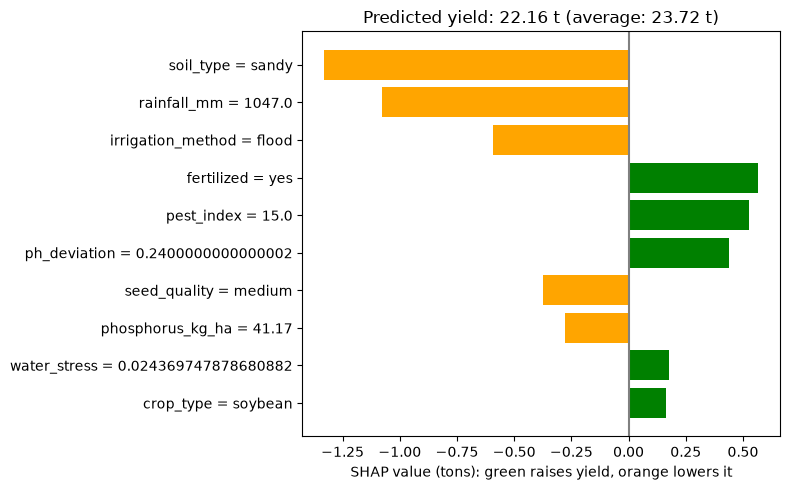

In [14]:
i = Xs.index[0]                         # first sampled field
row = shap_vals.loc[i]
top = row.reindex(row.abs().sort_values(ascending=False).index[:10])

plt.figure(figsize=(8, 5))
plt.barh([f"{f} = {Xs.loc[i, f]}" for f in top.index][::-1], top.values[::-1],
         color=np.where(top.values[::-1] >= 0, "green", "orange"))
plt.axvline(0, color="gray")
plt.title(f"Predicted yield: {final_model.predict(Xs.loc[[i]])[0]:.2f} t "
          f"(average: {base_value:.2f} t)")
plt.xlabel("SHAP value (tons): green raises yield, orange lowers it")
plt.tight_layout()
plt.show()

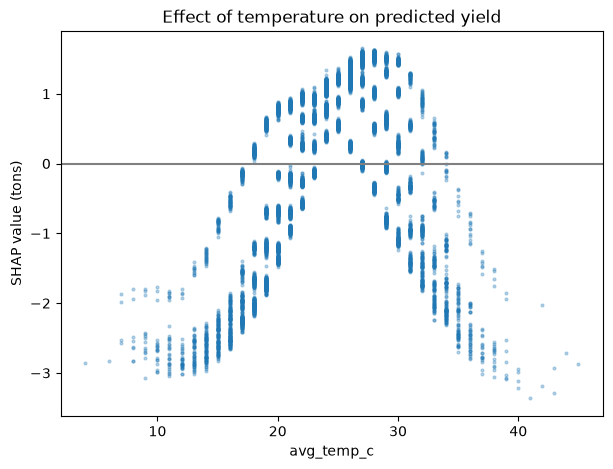

In [15]:
plt.figure(figsize=(7, 5))
plt.scatter(Xs["avg_temp_c"], shap_vals["avg_temp_c"], s=4, alpha=0.3)
plt.axhline(0, color="gray")
plt.xlabel("avg_temp_c")
plt.ylabel("SHAP value (tons)")
plt.title("Effect of temperature on predicted yield")
plt.show()

In [16]:
recon = base_value + shap_vals.sum(axis=1).values
print("Additivity check passed:", np.allclose(recon, final_model.predict(Xs), atol=1e-4))

Additivity check passed: True


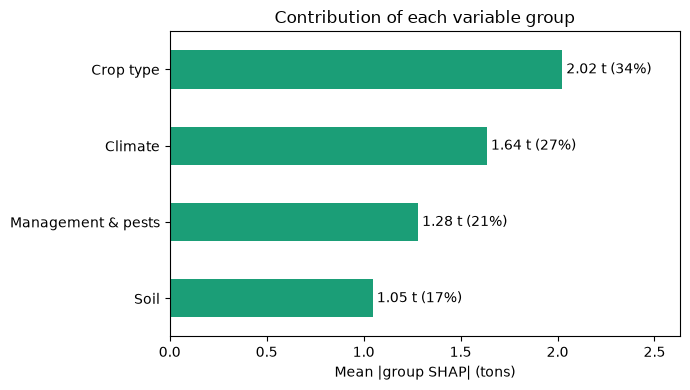

Crop type             33.8
Climate               27.3
Management & pests    21.4
Soil                  17.5
dtype: float64


In [17]:
groups = {
    "Climate": ["avg_temp_c", "rainfall_mm", "humidity_pct", "weather_zone", "season",
                "rain_x_temp", "temp_sq", "rain_per_humidity", "water_stress", "total_water_mm"],
    "Soil": ["soil_ph", "soil_type", "nitrogen_kg_ha", "phosphorus_kg_ha", "potassium_kg_ha",
             "npk_total", "n_to_p", "n_to_k", "p_to_k", "ph_deviation", "soil_ph_missing",
             "phosphorus_kg_ha_missing", "potassium_kg_ha_missing"],
    "Management & pests": ["fertilized", "irrigation_mm", "irrigation_method",
                           "seed_quality", "days_from_last_harvest", "pest_index"],
    "Crop type": ["crop_type"],
}
group_imp = pd.Series({g: shap_vals[fs].sum(axis=1).abs().mean() for g, fs in groups.items()})
group_imp = group_imp.sort_values(ascending=False)
share = group_imp / group_imp.sum() * 100

plt.figure(figsize=(7, 4))
group_imp[::-1].plot(kind="barh", color="#1b9e77")
for i, (g, v) in enumerate(group_imp[::-1].items()):
    plt.text(v, i, f" {v:.2f} t ({share[g]:.0f}%)", va="center")
plt.xlabel("Mean |group SHAP| (tons)")
plt.title("Contribution of each variable group")
plt.xlim(0, group_imp.max() * 1.3)
plt.tight_layout()
plt.savefig("shap_group_importance.png", dpi=200, bbox_inches="tight")
plt.show()
print(share.round(1))

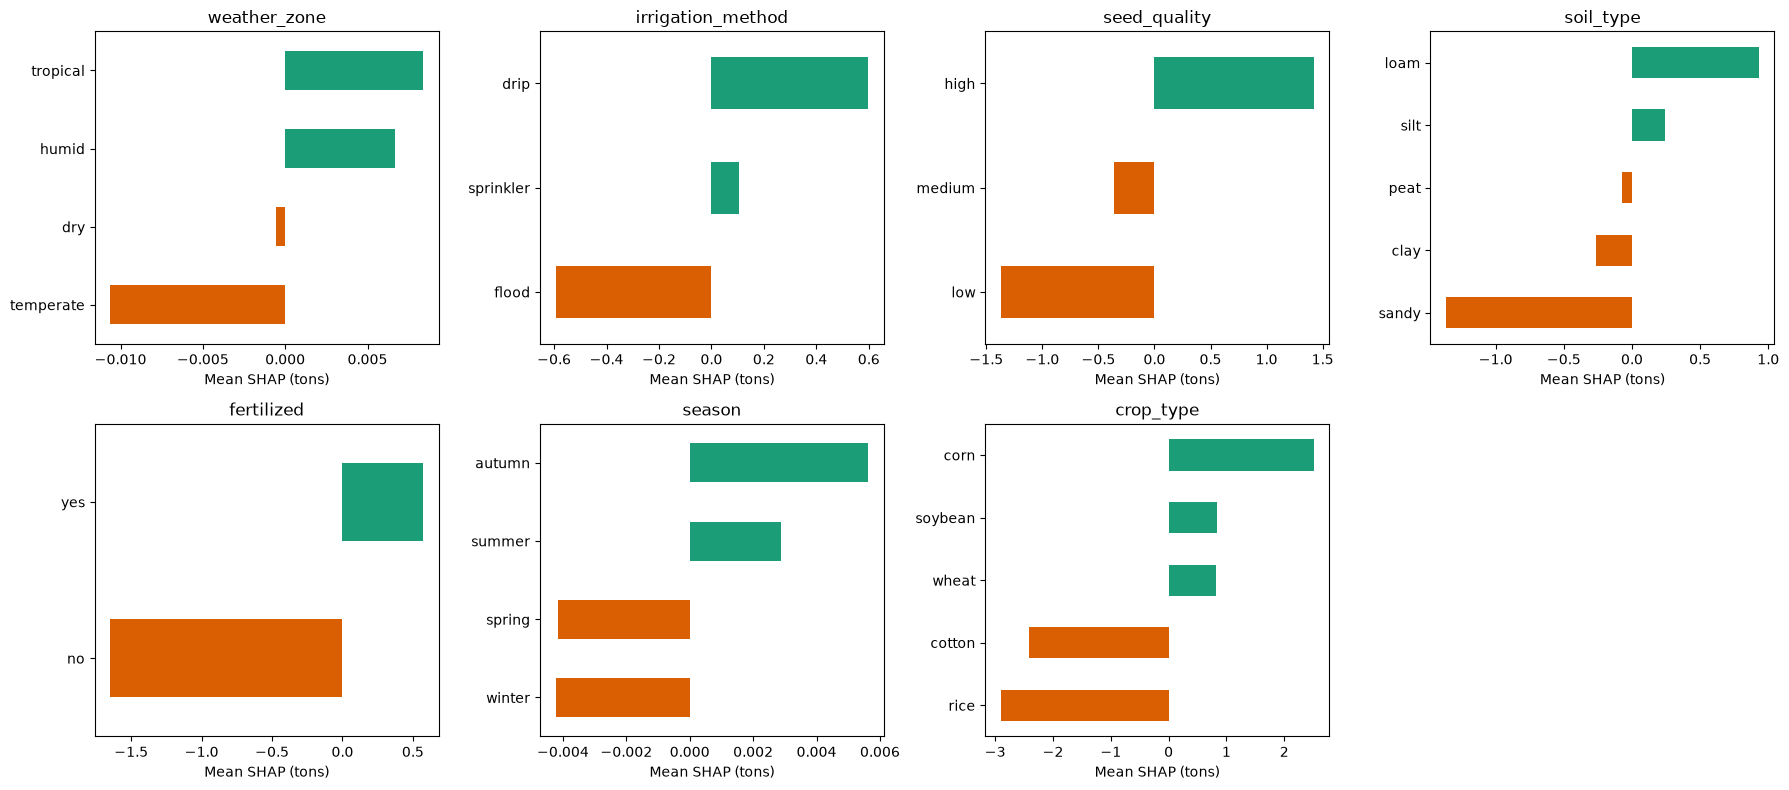

In [18]:
cat_cols = Xs.select_dtypes("category").columns
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    eff = shap_vals[c].groupby(Xs[c], observed=True).mean().sort_values()
    eff.plot(kind="barh", ax=ax, color=np.where(eff >= 0, "#1b9e77", "#d95f02"))
    ax.set_title(c)
    ax.set_xlabel("Mean SHAP (tons)")
    ax.set_ylabel("")
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("shap_categorical_effects.png", dpi=200, bbox_inches="tight")
plt.show()

In [19]:
raw = df.drop(columns=[TARGET])
baseline = {c: (raw[c].mode()[0] if c in CAT_COLS else raw[c].median()) for c in raw.columns}

def make_rows(changes_list):
    rows = pd.DataFrame([{**baseline, **ch} for ch in changes_list])[raw.columns]
    return add_features(rows)

print("Typical field:", baseline)
print("Predicted yield:", round(final_model.predict(make_rows([{}]))[0], 2), "tons")

Typical field: {'weather_zone': 'temperate', 'irrigation_method': 'sprinkler', 'soil_ph': np.float64(6.51), 'irrigation_mm': np.float64(147.0), 'days_from_last_harvest': np.float64(83.0), 'seed_quality': 'medium', 'soil_type': 'loam', 'fertilized': 'yes', 'nitrogen_kg_ha': np.float64(121.27), 'season': 'winter', 'rainfall_mm': np.float64(837.0), 'avg_temp_c': np.float64(24.0), 'crop_type': 'corn', 'phosphorus_kg_ha': np.float64(56.57), 'humidity_pct': np.float64(85.81), 'pest_index': np.float64(26.0), 'potassium_kg_ha': np.float64(67.2)}
Predicted yield: 31.24 tons


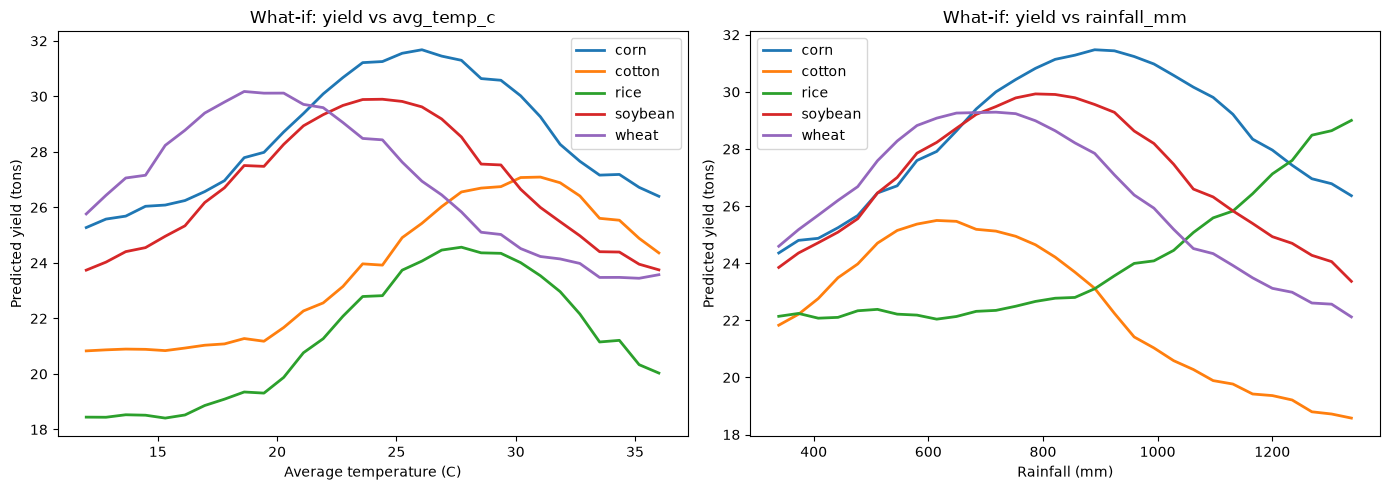

In [20]:
crops = sorted(raw["crop_type"].unique())
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, feat, label in zip(axes, ["avg_temp_c", "rainfall_mm"],
                           ["Average temperature (C)", "Rainfall (mm)"]):
    grid = np.linspace(raw[feat].quantile(0.01), raw[feat].quantile(0.99), 30)
    for crop in crops:
        X_s = make_rows([{"crop_type": crop, feat: v} for v in grid])
        ax.plot(grid, final_model.predict(X_s), label=crop, lw=2)
    ax.set_xlabel(label)
    ax.set_ylabel("Predicted yield (tons)")
    ax.set_title(f"What-if: yield vs {feat}")
    ax.legend()

plt.tight_layout()
plt.savefig("whatif_temp_rain.png", dpi=200, bbox_inches="tight")
plt.show()

In [21]:
rows = []
for crop in crops:
    for fert in ["no", "yes"]:
        for seed in ["low", "medium", "high"]:
            rows.append({"crop_type": crop, "fertilized": fert, "seed_quality": seed})

pred = final_model.predict(make_rows(rows))
table = pd.DataFrame(rows).assign(predicted_yield=pred.round(2))
print(table.pivot_table(index=["crop_type", "fertilized"], columns="seed_quality",
                        values="predicted_yield"))

seed_quality           high    low  medium
crop_type fertilized                      
corn      no          30.33  28.17   29.11
          yes         33.18  30.26   31.24
cotton    no          22.89  20.84   21.77
          yes         25.95  23.04   23.97
rice      no          21.76  19.69   20.64
          yes         24.80  21.87   22.81
soybean   no          28.94  26.96   27.91
          yes         31.71  28.92   29.89
wheat     no          27.53  25.51   26.48
          yes         30.35  27.51   28.48


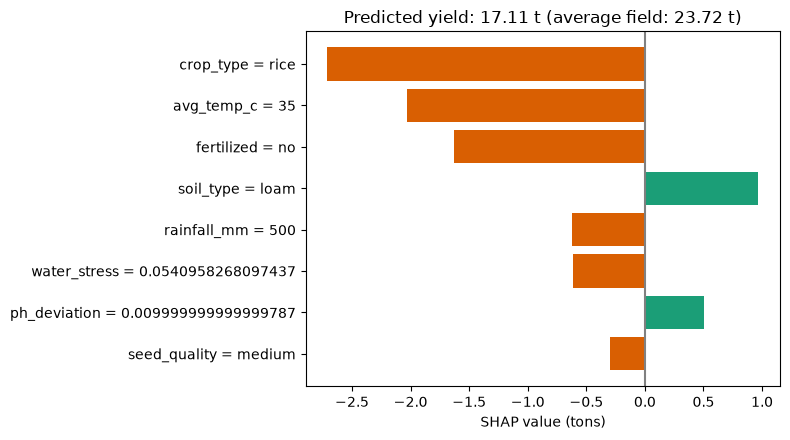

In [22]:
def explain_scenario(changes, top_n=8):
    X_s = make_rows([changes])
    pred = final_model.predict(X_s)[0]
    c = final_model.predict(X_s, pred_contrib=True)[0]
    contrib = pd.Series(c[:-1], index=X_s.columns)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index[:top_n])
    labels = [f"{f} = {X_s.iloc[0][f]}" for f in top.index]
    plt.figure(figsize=(8, 4.5))
    plt.barh(labels[::-1], top.values[::-1],
             color=np.where(top.values[::-1] >= 0, "#1b9e77", "#d95f02"))
    plt.axvline(0, color="gray")
    plt.title(f"Predicted yield: {pred:.2f} t (average field: {c[-1]:.2f} t)")
    plt.xlabel("SHAP value (tons)")
    plt.tight_layout()
    plt.show()

# Try it: a hot, dry rice field with no fertiliser
explain_scenario({"crop_type": "rice", "avg_temp_c": 35, "rainfall_mm": 500, "fertilized": "no"})

In [23]:
# Paste as a NEW CELL at the very END of your optimised notebook and run it once.
# It saves the models and the information the web app needs into ./app_assets
import json
import os

import joblib
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

os.makedirs("app_assets", exist_ok=True)

# 1. Optimised model (LightGBM)
joblib.dump(final_model, "app_assets/lgbm_optimised.joblib")

# 2. Basic model: Linear Regression (retrains in about 5 seconds)
lr_pipe = Pipeline([("prep", preprocess), ("model", LinearRegression())])
lr_pipe.fit(Xb_train, yb_train)
joblib.dump(lr_pipe, "app_assets/linear_basic.joblib")

# 3. OPTIONAL basic model: Random Forest.
# The default Random Forest (100 fully grown trees) can create a file of several GB,
# so it is switched off. Set SAVE_RF = True only if you have the disk space.
SAVE_RF = False
if SAVE_RF:
    rf_pipe = pipe          # the last pipeline trained in the section 8 loop = Random Forest
    assert type(rf_pipe.named_steps["model"]).__name__ == "RandomForestRegressor"
    joblib.dump(rf_pipe, "app_assets/rf_basic.joblib", compress=3)

# 4. Information for the input form (ranges, categories, defaults)
raw = df.drop(columns=[TARGET])
meta = {
    "columns": list(raw.columns),
    "cat_options": {c: sorted(raw[c].dropna().unique().tolist()) for c in CAT_COLS},
    "cat_defaults": {c: str(raw[c].mode()[0]) for c in CAT_COLS},
    "num_ranges": {
        c: {"min": float(raw[c].quantile(0.01)),      # stay inside the range the model saw
            "max": float(raw[c].quantile(0.99)),
            "default": float(raw[c].median())}
        for c in RAW_NUM
    },
}
with open("app_assets/meta.json", "w") as f:
    json.dump(meta, f, indent=2)

# 5. Comparison table for the "Model comparison" tab
comparison.round(4).to_csv("app_assets/comparison.csv")

for name in sorted(os.listdir("app_assets")):
    size_mb = os.path.getsize(os.path.join("app_assets", name)) / 1e6
    print(f"{name:25s} {size_mb:8.1f} MB")

comparison.csv                 0.0 MB
lgbm_optimised.joblib          4.9 MB
linear_basic.joblib            0.0 MB
meta.json                      0.0 MB


In [24]:
print(final_model.predict(make_rows([{
    "rainfall_mm": 840, "humidity_pct": 86.0, "soil_ph": 6.5,
    "nitrogen_kg_ha": 121.0, "phosphorus_kg_ha": 57.0, "potassium_kg_ha": 67.0
}]))[0])

31.290228879165504
